number of gaps: 542
shortest gap: 2.2 ms
longest gap:  1665.5 ms


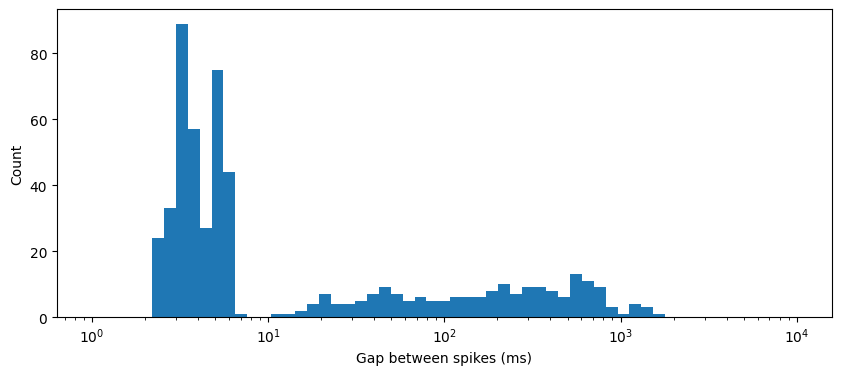

In [1]:
import numpy as np
import matplotlib.pyplot as plt

"""Two spikes less than 10 ms apart belong to the same event.
An event with one spike is a single spike. An event with two or more is a burst."""

data = np.load("../data/processed/simulation_60s.npz")
spike_times = data["spike_times"]
spike_heights = data["spike_heights"]

# detrmining gap between each spike and the one before it
gaps_ms = []
for i in range(1, len(spike_times)):
    gap = spike_times[i] - spike_times[i - 1]
    gaps_ms.append(gap)

print("number of gaps:", len(gaps_ms))
print("shortest gap:", round(min(gaps_ms), 1), "ms")
print("longest gap: ", round(max(gaps_ms), 1), "ms")

# a histogram of the gaps
bin_edges = np.logspace(0, 4, 60)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(gaps_ms, bins=bin_edges)
ax.set_xscale("log")
ax.set_xlabel("Gap between spikes (ms)")
ax.set_ylabel("Count")
plt.show()

In [2]:
from neural_recording_chain.events import group_into_events, split_singles_and_bursts

events = group_into_events(spike_times)
single_spikes, bursts = split_singles_and_bursts(events)

print("events:       ", len(events))
print("single spikes:", len(single_spikes))
print("bursts:       ", len(bursts))

# how many spikes does each burst have?
for size in [2, 3, 4, 5]:
    count = 0
    for burst in bursts:
        if len(burst) == size:
            count = count + 1
    print("bursts with", size, "spikes:", count)

events:        193
single spikes: 32
bursts:        161
bursts with 2 spikes: 5
bursts with 3 spikes: 123
bursts with 4 spikes: 33
bursts with 5 spikes: 0


In [3]:
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV, slow_wave_uV
from neural_recording_chain.filter import bandpass_filter
from neural_recording_chain.adc import digitise
from neural_recording_chain.detector import detect_spikes
from neural_recording_chain.events import count_detections_per_event

# build the noisy recording and run the full chain
time_ms = data["time_ms"]
v_electrode_uV = data["v_electrode_uV"]
n_samples = len(v_electrode_uV)

recording_uV = (v_electrode_uV + thermal_noise_uV(n_samples, dt_ms=0.05)
                + background_noise_uV(n_samples, dt_ms=0.05) + slow_wave_uV(n_samples, dt_ms=0.05))

filtered_uV = bandpass_filter(recording_uV, dt_ms=0.05)
digitised_uV, step_uV = digitise(filtered_uV, n_bits=8, input_range_uV=500.0)
detected_times, threshold_uV = detect_spikes(digitised_uV, time_ms, threshold_factor=4.5, min_gap_ms=3.0)
print("detections in total:", len(detected_times))

single_counts = count_detections_per_event(single_spikes, detected_times)
burst_counts = count_detections_per_event(bursts, detected_times)

for n_detections in [0, 1, 2, 3, 4]:
    print("single spikes with", n_detections, "detections:", single_counts.count(n_detections))

for n_detections in [0, 1, 2, 3, 4]:
    print("bursts with", n_detections, "detections:", burst_counts.count(n_detections))

detections in total: 254
single spikes with 0 detections: 0
single spikes with 1 detections: 32
single spikes with 2 detections: 0
single spikes with 3 detections: 0
single spikes with 4 detections: 0
bursts with 0 detections: 0
bursts with 1 detections: 105
bursts with 2 detections: 52
bursts with 3 detections: 4
bursts with 4 detections: 0
